In [117]:
from pydoc import describe

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import shapiro
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, \
    f1_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from statsmodels.stats.descriptivestats import Describe

from scipy.stats.mstats import winsorize
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [74]:
data = pd.read_csv('./data/bank.csv',na_values=['-',' ',''])
data.info()
data.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction.Score,Point.Earned
count,4898.000000,4895.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.00000
mean,650.457125,38.978141,5.014292,76802.313328,1.523887,0.708044,0.508983,100307.995906,0.208861,3.005717,603.87893
std,97.521368,10.613724,2.875647,62425.535914,0.582872,0.454709,0.499970,57659.586058,0.406536,1.399688,227.45121
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000,1.000000,119.00000
25%,583.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,50803.347500,0.000000,2.000000,404.25000
50%,652.000000,37.000000,5.000000,97346.425000,1.000000,1.000000,1.000000,100440.680000,0.000000,3.000000,604.00000
75%,718.000000,44.000000,8.000000,127969.195000,2.000000,1.000000,1.000000,149071.945000,0.000000,4.000000,798.00000
max,850.000000,88.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199970.740000,1.000000,5.000000,1000.00000


In [75]:
data['Stayed'] = np.where(data['Exited']==0,'Yes','No')
data['Stayed'] = data['Stayed'].map({'Yes':1,'No':0})

data.drop(columns=['Exited'], inplace=True)

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4897 non-null   str    
 1   CreditScore         4898 non-null   int64  
 2   Geography           4897 non-null   str    
 3   Gender              4898 non-null   str    
 4   Age                 4896 non-null   str    
 5   Tenure              4898 non-null   int64  
 6   Balance             4898 non-null   float64
 7   NumOfProducts       4898 non-null   int64  
 8   HasCrCard           4898 non-null   int64  
 9   IsActiveMember      4898 non-null   int64  
 10  EstimatedSalary     4898 non-null   float64
 11  Satisfaction.Score  4898 non-null   int64  
 12  Card.Type           4898 non-null   str    
 13  Point.Earned        4898 non-null   int64  
 14  Stayed              4898 non-null   int64  
dtypes: float64(2), int64(8), str(5)
memory usage: 574.1 KB


In [76]:
data.isna().sum()
data.drop(columns=['Surname'], inplace=True)


In [14]:
data.isna().sum()

CreditScore           0
Geography             1
Gender                0
Age                   2
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64

In [77]:
data['Age'].fillna(data['Age'].median())

0       37.0
1       41.0
2       42.0
3       39.0
4       43.0
        ... 
4893    32.0
4894    31.0
4895    41.0
4896    40.0
4897    40.0
Name: Age, Length: 4898, dtype: float64

In [26]:
data.isna().sum()

CreditScore           0
Geography             2
Gender                0
Age                   3
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64

In [27]:
data['Age'].fillna(data['Age'].median())

0       37.0
1       41.0
2       42.0
3       39.0
4       43.0
        ... 
4893    32.0
4894    31.0
4895    41.0
4896    40.0
4897    40.0
Name: Age, Length: 4898, dtype: float64

In [78]:

data['Age']=data['Age'].fillna(data['Age'].median())
data.isna().sum()


CreditScore           0
Geography             2
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64

In [30]:
data['Geography'].unique()

<StringArray>
['France', 'Spain', 'Germany', nan]
Length: 4, dtype: str

In [79]:
data['Geography'] = data['Geography'].fillna(data['Geography'].mode()[0])

In [33]:
data['Geography'].unique()


<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [34]:
data.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction.Score,Point.Earned,Stayed
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.00000,4898.000000
mean,650.457125,38.976929,5.014292,76802.313328,1.523887,0.708044,0.508983,100307.995906,3.005717,603.87893,0.791139
std,97.521368,10.610585,2.875647,62425.535914,0.582872,0.454709,0.499970,57659.586058,1.399688,227.45121,0.406536
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,1.000000,119.00000,0.000000
25%,583.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,50803.347500,2.000000,404.25000,1.000000
50%,652.000000,37.000000,5.000000,97346.425000,1.000000,1.000000,1.000000,100440.680000,3.000000,604.00000,1.000000
75%,718.000000,44.000000,8.000000,127969.195000,2.000000,1.000000,1.000000,149071.945000,4.000000,798.00000,1.000000
max,850.000000,88.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199970.740000,5.000000,1000.00000,1.000000


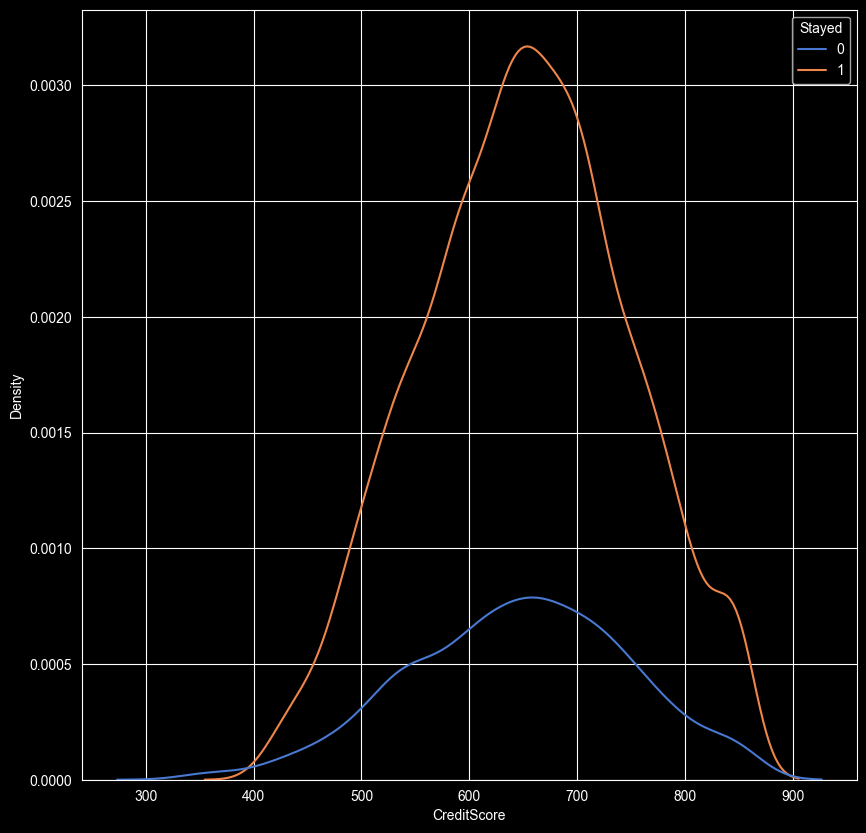

In [80]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='CreditScore',hue='Stayed',palette='muted')
plt.show()

data.drop(columns=['CreditScore'], inplace=True)

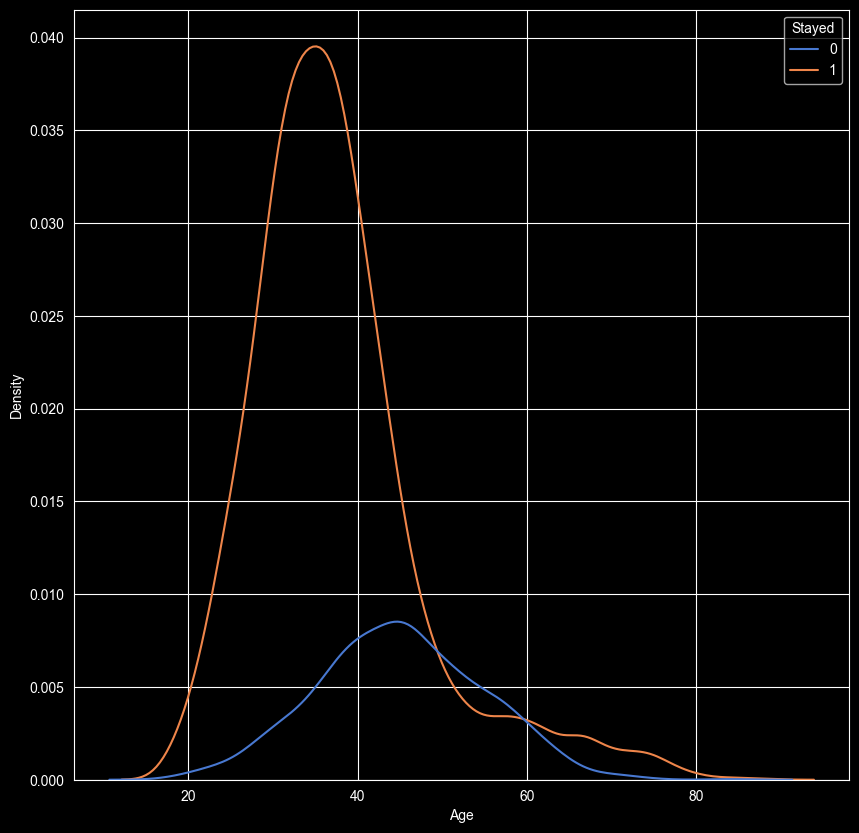

In [39]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Age',hue='Stayed',palette='muted')
plt.show()

# data.drop(columns=['CreditScore'], inplace=True)

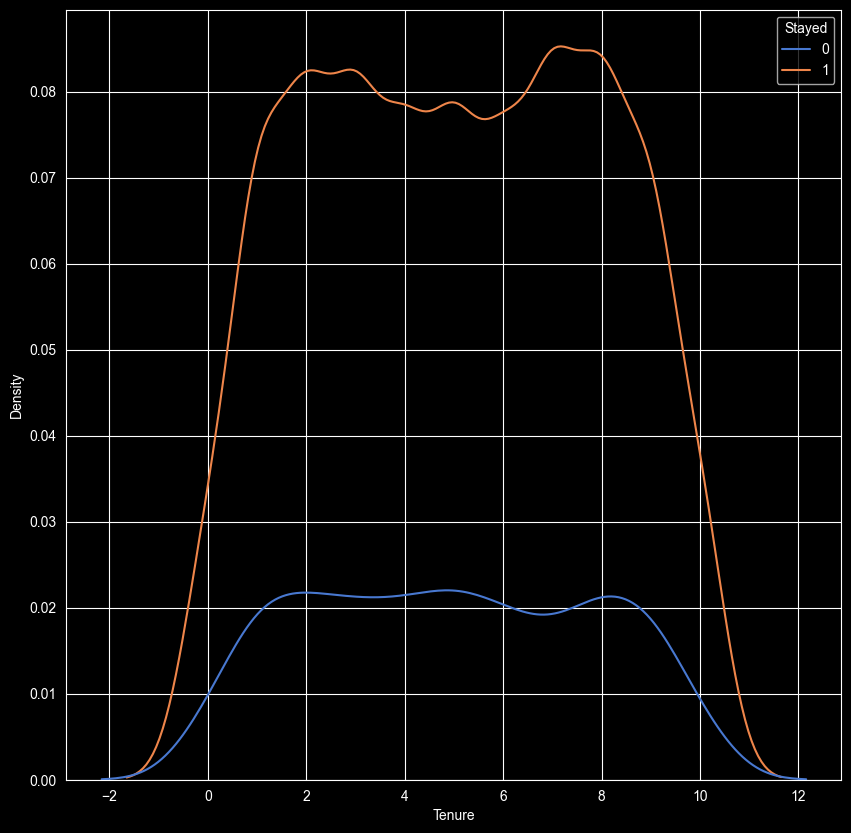

In [81]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Tenure',hue='Stayed',palette='muted')
plt.show()

data.drop(columns=['Tenure'], inplace=True)

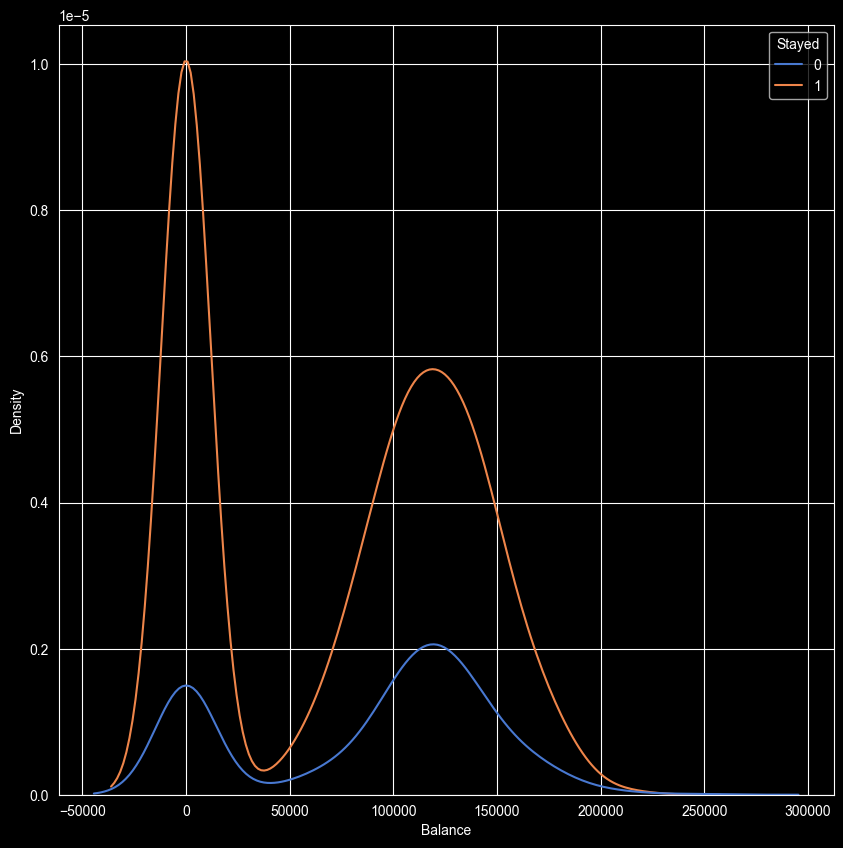

In [82]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Balance',hue='Stayed',palette='muted')
plt.show()

data.drop(columns=['Balance'], inplace=True)

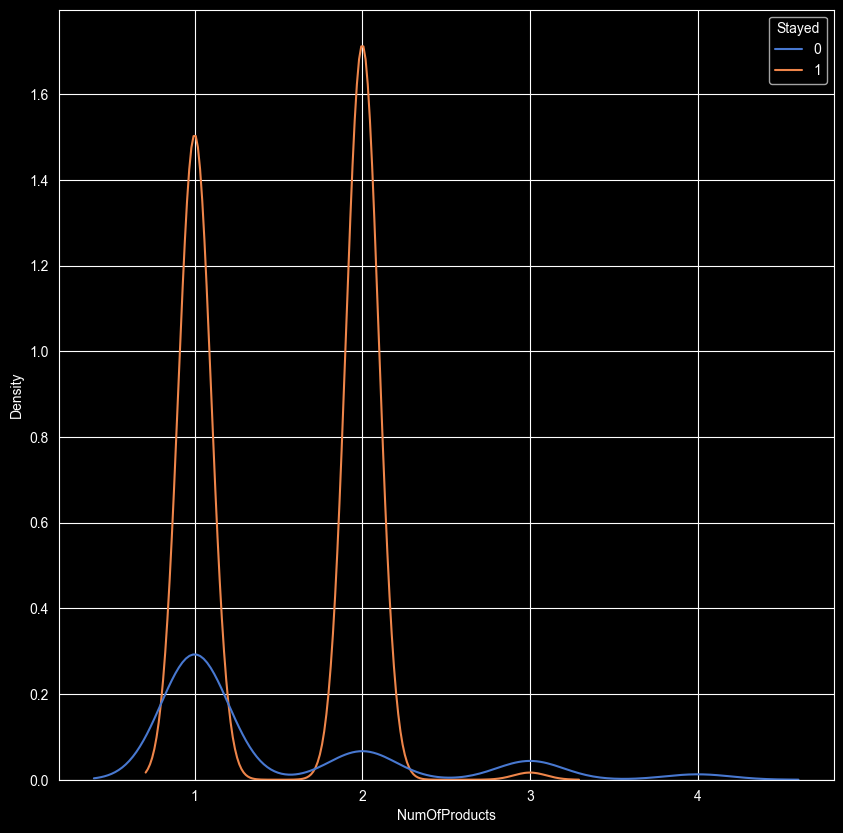

In [44]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='NumOfProducts',hue='Stayed',palette='muted')
plt.show()


# data.drop(columns=['CreditScore'], inplace=True)

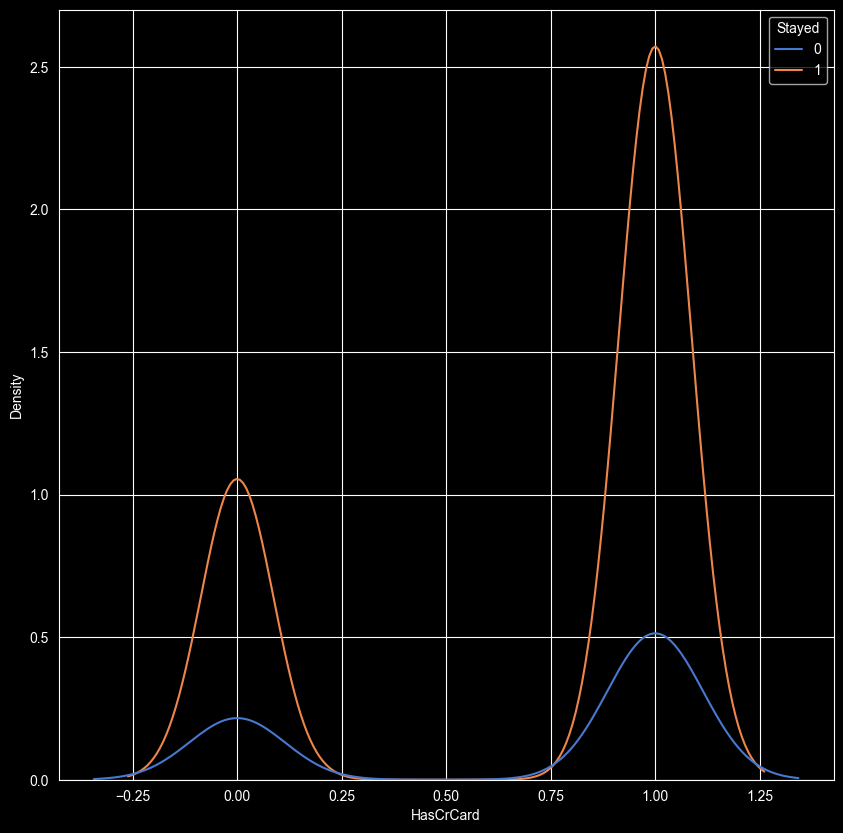

In [83]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='HasCrCard',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['HasCrCard'], inplace=True)

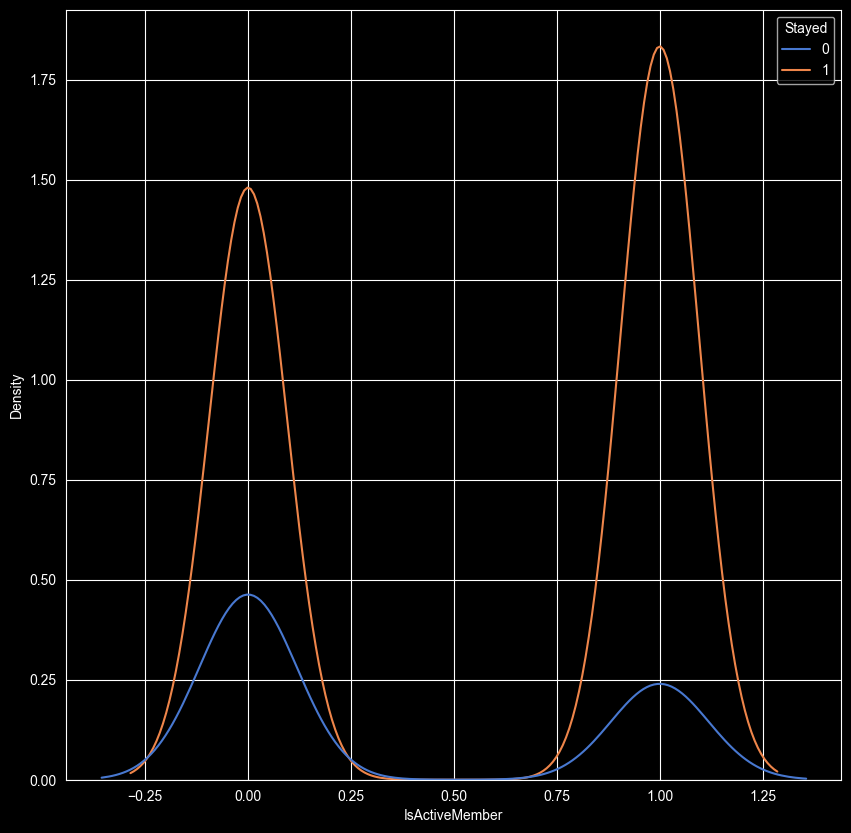

In [84]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='IsActiveMember',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['IsActiveMember'], inplace=True)

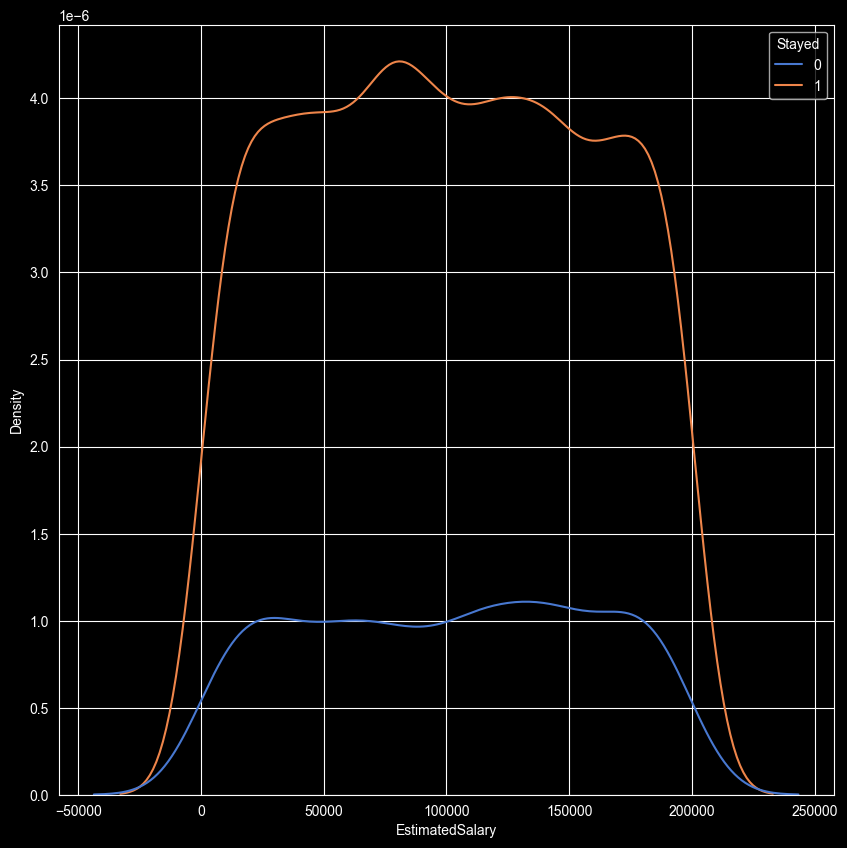

In [85]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='EstimatedSalary',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['EstimatedSalary'], inplace=True)

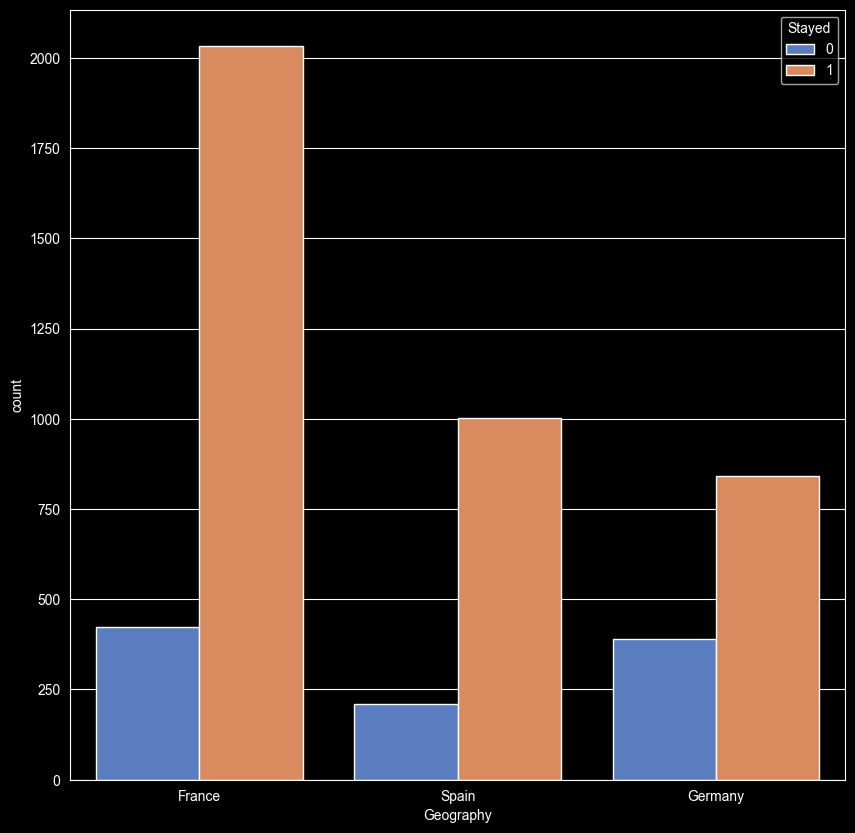

In [54]:
plt.figure(figsize=(10,10))
sns.countplot(data=data,x='Geography',hue='Stayed',palette='muted')
plt.show()
# data.drop(columns=['Geography'], inplace=True)

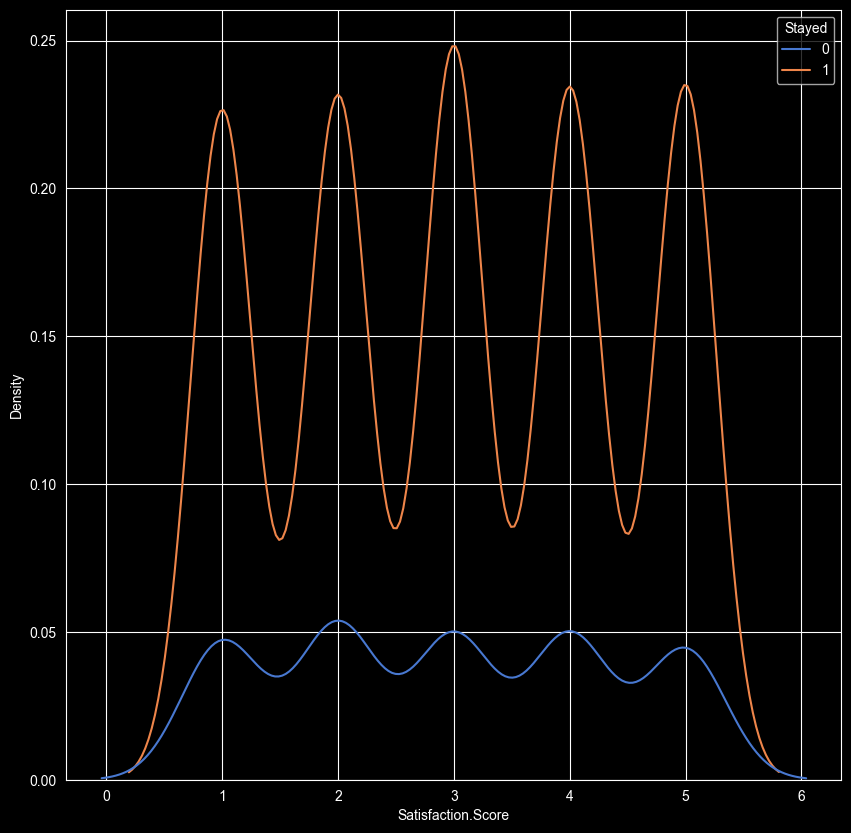

In [86]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Satisfaction.Score',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['Satisfaction.Score'], inplace=True)

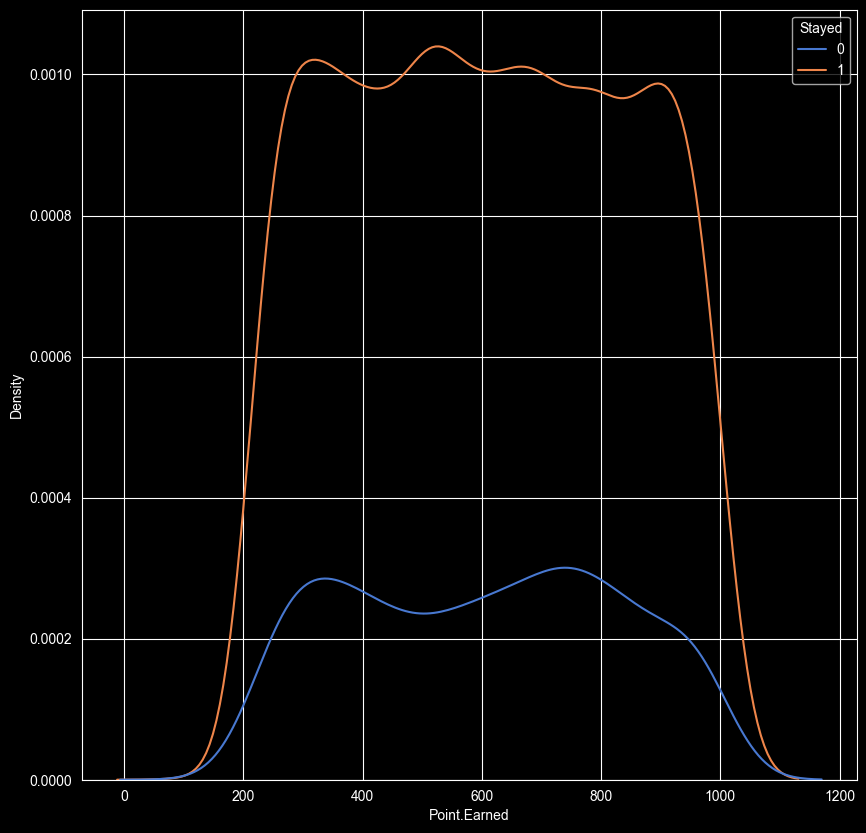

In [87]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Point.Earned',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['Point.Earned'], inplace=True)

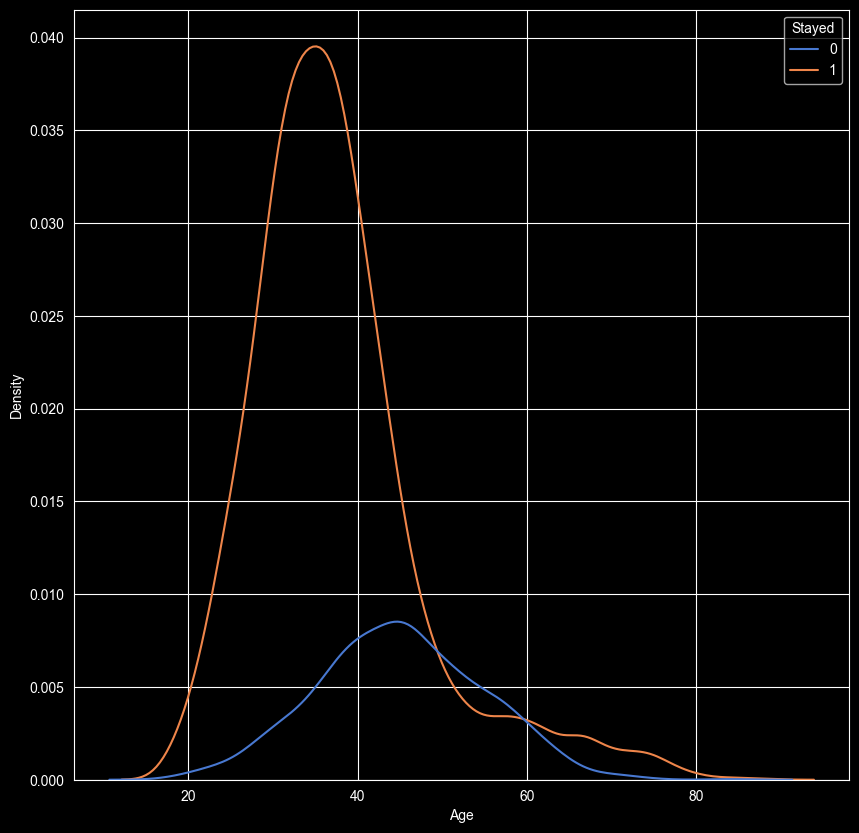

In [60]:
plt.figure(figsize=(10,10))
sns.kdeplot(data=data,x='Age',hue='Stayed',palette='muted')
plt.show()
# data.drop(columns=['Age'], inplace=True)

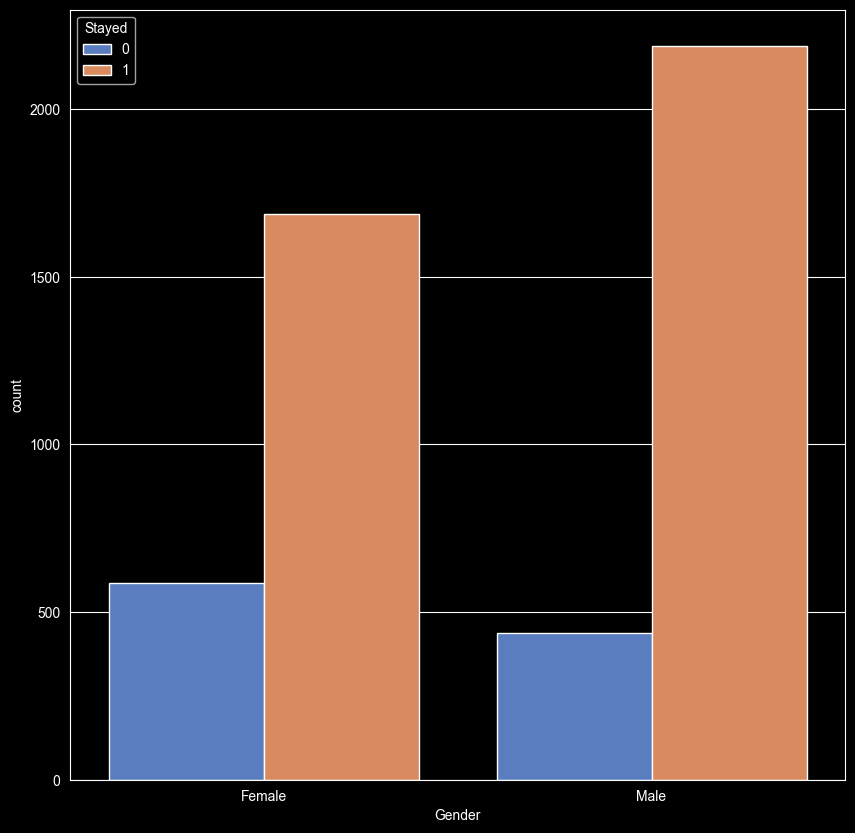

In [62]:
plt.figure(figsize=(10,10))
sns.countplot(data=data,x='Gender',hue='Stayed',palette='muted')
plt.show()
# data.drop(columns=['Gender'], inplace=True)

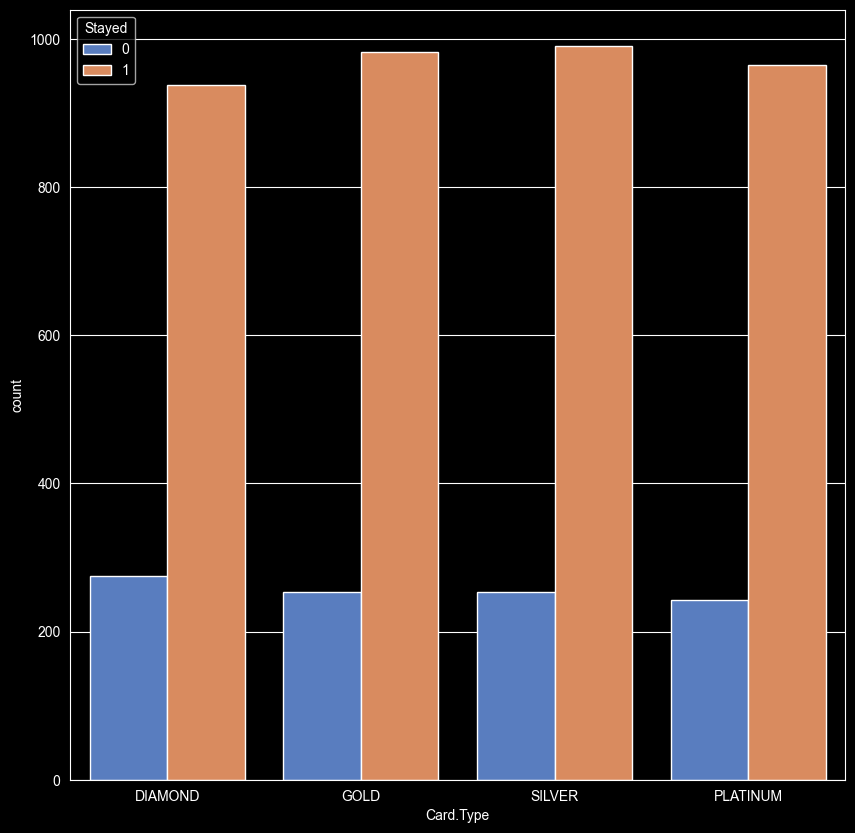

In [88]:
plt.figure(figsize=(10,10))
sns.countplot(data=data,x='Card.Type',hue='Stayed',palette='muted')
plt.show()
data.drop(columns=['Card.Type'], inplace=True)

In [65]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Geography      4898 non-null   str    
 1   Gender         4898 non-null   str    
 2   Age            4898 non-null   float64
 3   NumOfProducts  4898 non-null   int64  
 4   Stayed         4898 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 191.5 KB


In [66]:
data['Gender'].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

# **OHE ALGORITAM**

In [91]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
p = ['Geography','Gender']

enc = ohe.fit_transform(data[p])
enc_col =ohe.get_feature_names_out(p)

data_ohe = pd.DataFrame(enc, columns=enc_col,index=data.index)
data = data.drop(columns=p).join(data_ohe)

In [92]:
X = data.drop(columns='Stayed')
y=data['Stayed']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=10,stratify=y)

In [105]:
tree = DecisionTreeClassifier()
cv= StratifiedKFold(n_splits=10,random_state=10,shuffle=True)

param_grid = {'ccp_alpha':np.arange(0.0,0.05,0.0025)}

k = GridSearchCV(
        estimator=tree,
        param_grid=param_grid,
        cv=cv,
        scoring='accuracy'
    )

k.fit(X_train,y_train)





,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': array([0. ...045 , 0.0475])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also d

In [120]:
knn = KNeighborsClassifier()

params = {'knn':list(range(3,26,2))}

r=GridSearchCV(estimator=knn,
               param_grid=params,
               cv=10,
               scoring='accuracy')


In [106]:
best_k = k.best_params_['ccp_alpha']
print(best_k)

0.0025


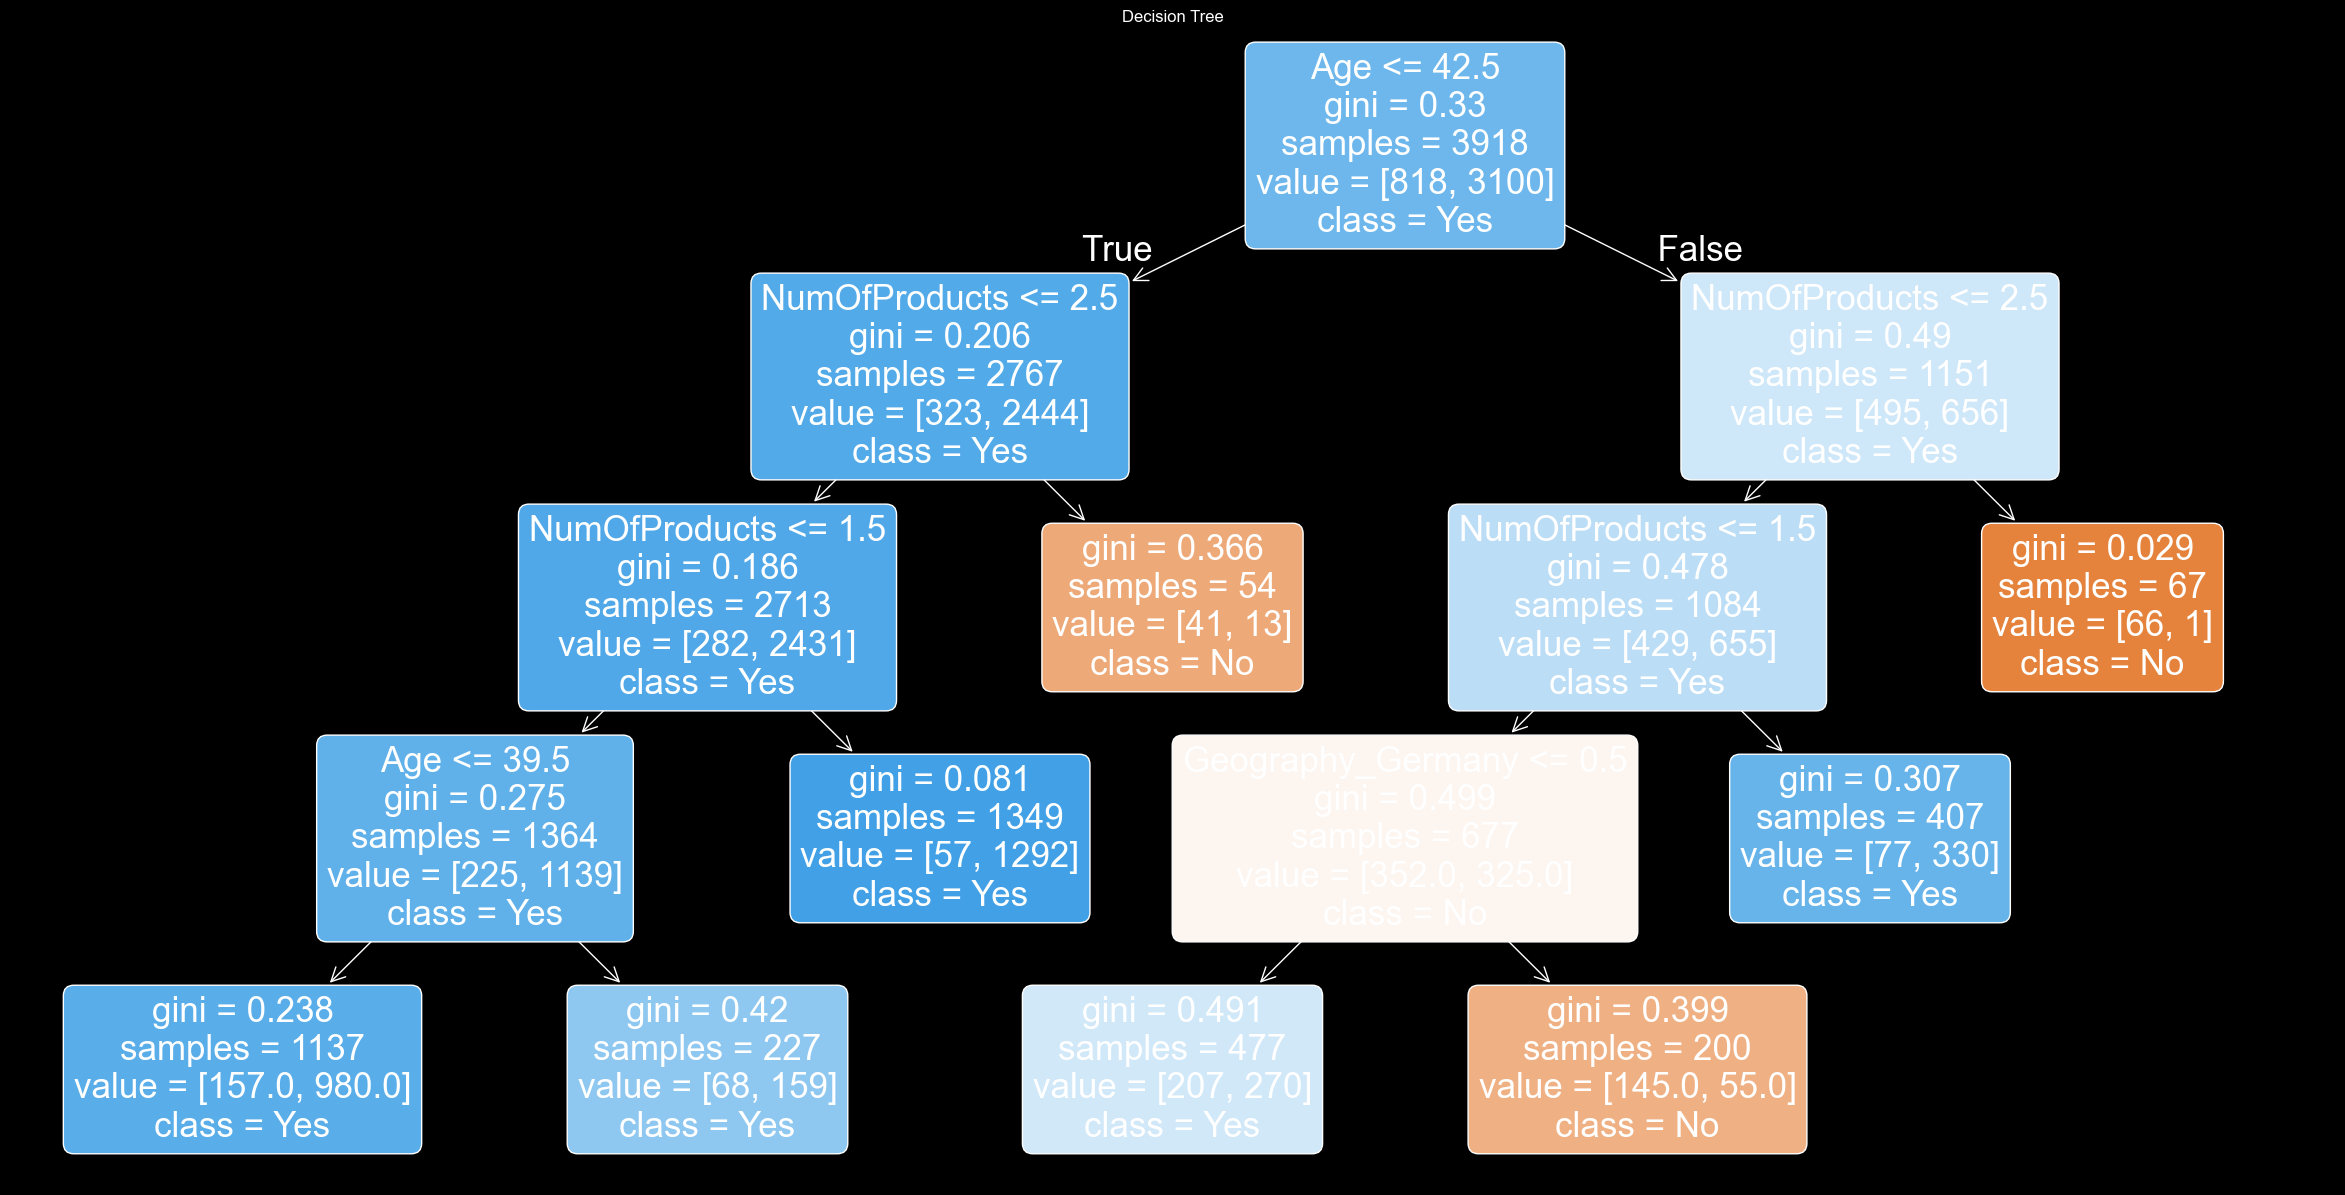

In [110]:
tree = DecisionTreeClassifier(ccp_alpha=best_k,random_state=42).fit(X_train,y_train)

plt.figure(figsize=(30,15))
plot_tree(tree,feature_names=X_train.columns,class_names=['No','Yes'],filled=True,rounded=True)
plt.title('Decision Tree')
plt.show()

In [111]:
y_pred = tree.predict(X_test)

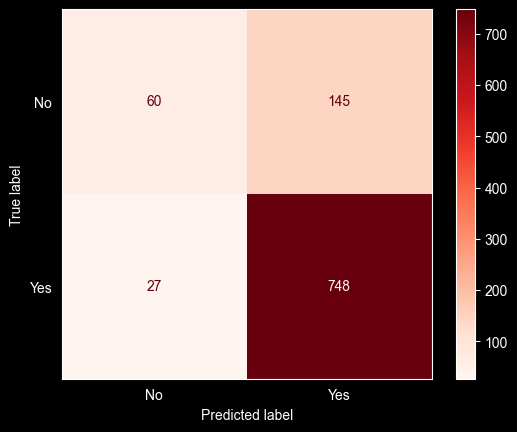

In [114]:
cm = confusion_matrix(y_test,y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['No','Yes'])
disp.plot(cmap=plt.cm.Reds)
plt.grid()
plt.show()